# Prepaid Card Marketing — Mini-Project 2
## Part 4 of 5: Card company marketing and origination strategy (Task C)

**Purpose.** Translate the chosen model into a practical, responsible card-company strategy: who is most likely to use a reloadable prepaid card, which signals can be reached in practice, and how the product should be marketed and originated.

### Executive summary

- The chosen model is the class-weighted logistic regression from Task B. It ranks people by likely prepaid-card use; its cross-validated ROC-AUC is 0.728 and its test ROC-AUC is 0.739.
- The recommended rule is to review the top 20% of scores, using the training-set cutoff of about 0.600. In the test set this group contains about 55% of users and has roughly 2.9 times the overall usage rate.
- The clearest associations are with financial access and strain: not having a bank account, low savings or liquidity, material hardship, SNAP receipt, credit distress, renting, and lower tested financial knowledge. Savings, ability to raise $2,000, and financial well-being overlap and should be treated as one liquidity signal rather than three independent customer types.
- A company-observable model retains nearly the same lift as the full survey model. Targeting should therefore use observable financial-access, credit, demographic, and payment-history signals—not race/ethnicity or survey-only hardship and knowledge measures.
- The opportunity is mainstream as well as underserved: most prepaid-card users have a bank account. Marketing should offer a transparent, useful transaction tool rather than assume that every prospect is unbanked or financially unsophisticated.

All results are associations in a 2016 self-reported survey. They are not causal effects, national estimates, or predictions of fee revenue.

---
# 1. Setup

This notebook uses the fixed train/test split, 20 predictors, and chosen-model scores produced by Tasks A and B. The training scores are out-of-fold scores and are used for profiling without leakage; the test scores are used only to confirm the final patterns.

In [1]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import prep
from prep import build_preprocessor, feature_lists, feature_table, load_split, readable_names

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
TOP_SHARE = 0.20

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})

def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out

X_train, X_test, y_train, y_test = load_split()
train_scores = pd.read_csv(DATA_DIR / "train_oof_scores.csv", index_col="PUF_ID")
test_scores = pd.read_csv(DATA_DIR / "test_scores.csv", index_col="PUF_ID")
train_raw = pd.read_csv(DATA_DIR / "train.csv", index_col="PUF_ID")
test_raw = pd.read_csv(DATA_DIR / "test.csv", index_col="PUF_ID")
clean = pd.read_csv(DATA_DIR / "cfpb_clean.csv", index_col="PUF_ID")
features = feature_table()

assert train_scores.index.equals(train_raw.index)
assert test_scores.index.equals(test_raw.index)
assert train_scores["score_chosen"].notna().all() and test_scores["score_chosen"].notna().all()
base_rate = y_train.mean()
threshold = float(np.quantile(train_scores["score_chosen"], 1 - TOP_SHARE))
print(f"Training: {len(train_raw):,} respondents; test: {len(test_raw):,}; training usage rate: {base_rate:.1%}")
print(f"Fixed Task B rule: top {TOP_SHARE:.0%}; training cutoff {threshold:.3f} (reported as about 0.600)")

# Refit the documented chosen model so this notebook does not depend on a serialized scikit-learn version.
chosen_model = Pipeline([
    ("prep", build_preprocessor()),
    ("model", LogisticRegression(C=10, class_weight="balanced", max_iter=5000, random_state=SEED)),
])
chosen_model.fit(X_train, y_train)
refit_test_scores = chosen_model.predict_proba(X_test)[:, 1]
assert np.allclose(refit_test_scores, test_scores["score_chosen"].to_numpy(), atol=1e-8)
print("Refitted chosen model reproduces Task B test scores.")

Training: 5,093 respondents; test: 1,274; training usage rate: 8.8%
Fixed Task B rule: top 20%; training cutoff 0.600 (reported as about 0.600)
Refitted chosen model reproduces Task B test scores.


# 2. What drives the score?

The chosen model is logistic regression. A positive coefficient is associated with a higher score after accounting for the other predictors; a negative coefficient is associated with a lower score. For the standardised numeric predictors, `exp(coefficient)` is the odds ratio for a one-standard-deviation increase. The coefficients are not causal effects.

Because the saved Task B model keeps every category, its category coefficients are not comparisons with a single omitted baseline. For interpretable category odds ratios, the next cell refits the same model with the first numeric category omitted: Owns home, Self-employed, and Married are the reference categories.

In [2]:
# Full model coefficients for ranking the shared signals.
full_coef = pd.Series(
    chosen_model.named_steps["model"].coef_[0],
    index=readable_names(chosen_model.named_steps["prep"]),
    name="Coefficient",
)
coef_table = full_coef.sort_values(key=np.abs, ascending=False).to_frame()
coef_table["Odds ratio"] = np.exp(coef_table["Coefficient"])
display(fmt(coef_table.head(15), {"Coefficient": "{:+.3f}", "Odds ratio": "{:.2f}"}))

# Drop the first category of each unordered variable for category comparisons.
drop_first_model = Pipeline([
    ("prep", build_preprocessor(drop_first=True)),
    ("model", LogisticRegression(C=10, class_weight="balanced", max_iter=5000, random_state=SEED)),
])
drop_first_model.fit(X_train, y_train)
drop_scores = drop_first_model.predict_proba(X_test)[:, 1]
rank_agreement = pd.Series(drop_scores).corr(pd.Series(refit_test_scores), method="spearman")
assert rank_agreement > 0.99
category_coef = pd.Series(
    drop_first_model.named_steps["model"].coef_[0],
    index=readable_names(drop_first_model.named_steps["prep"]),
    name="Coefficient",
)
category_table = category_coef[category_coef.index.str.contains(":")].sort_values(key=np.abs, ascending=False).to_frame()
category_table["Odds ratio vs reference"] = np.exp(category_table["Coefficient"])
print(f"Spearman rank correlation between full and drop-first model scores: {rank_agreement:.3f}")
print("References: Owns home, Self-employed, and Married (the first coded category in each variable).")
display(fmt(category_table, {"Coefficient": "{:+.3f}", "Odds ratio vs reference": "{:.2f}"}))

,Coefficient,Odds ratio
Has: Checking or Savings Account at a bank or credit union,-0.546,0.58
Contacted by debt collector in past 12 months,+0.368,1.44
Marital Status: Widowed,+0.365,1.44
Primary or only employment status: Homemaker,-0.322,0.72
Any household member received SNAP benefits,+0.311,1.37
I applied for credit and was turned down,+0.279,1.32
Number of financial shocks in the past year (0-11),+0.253,1.29
Marital Status: Living with partner,-0.245,0.78
Which one of the following best describes your housing situation?: Owns home,-0.244,0.78
Which one of the following best describes your housing situation?: Rents,+0.238,1.27


Spearman rank correlation between full and drop-first model scores: 1.000
References: Owns home, Self-employed, and Married (the first coded category in each variable).


,Coefficient,Odds ratio vs reference
Has: Checking or Savings Account at a bank or credit union,-0.546,0.58
Which one of the following best describes your housing situation?: Rents,+0.485,1.62
Which one of the following best describes your housing situation?: Neither owns nor rents,+0.460,1.58
Marital Status: Widowed,+0.456,1.58
Primary or only employment status: Homemaker,-0.428,0.65
Primary or only employment status: Full-time student,-0.359,0.70
Marital Status: Never married,+0.195,1.22
Marital Status: Divorced / separated,+0.168,1.18
Has: Retirement Account (such as a 401k or IRA),-0.156,0.86
Marital Status: Living with partner,-0.154,0.86


### Liquidity is one overlapping theme

Savings, confidence in raising $2,000, and financial well-being are correlated measures of liquidity and security. Their individual weights should not be read as three separate causal levers. The business interpretation is a single liquidity/financial-security signal: prospects with fewer resources and less ability to absorb a shock tend to receive higher scores.

,Coefficient,Odds ratio per SD
How much money do you have in savings today...?,-0.047,0.95
"Confidence in ability to raise $2,000 in 30 days",+0.027,1.03
Financial well-being scale score,+0.065,1.07


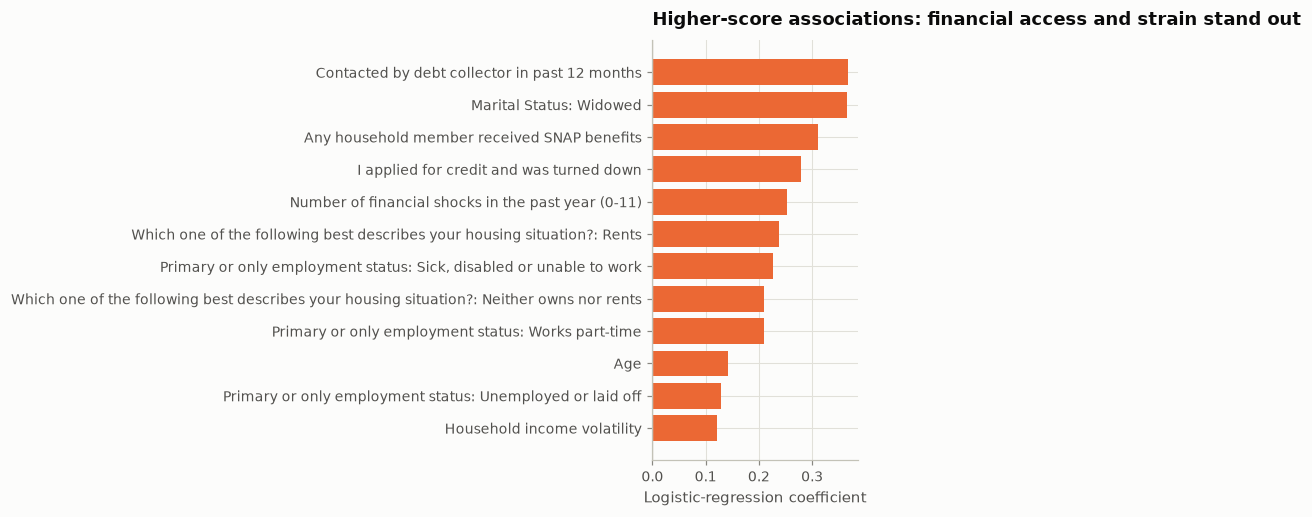

In [3]:
liquidity_terms = [
    "How much money do you have in savings today...?",
    "Confidence in ability to raise $2,000 in 30 days",
    "Financial well-being scale score",
]
liquidity = full_coef[full_coef.index.isin(liquidity_terms)].to_frame()
liquidity["Odds ratio per SD"] = np.exp(liquidity["Coefficient"])
display(fmt(liquidity, {"Coefficient": "{:+.3f}", "Odds ratio per SD": "{:.2f}"}))

plot_coef = full_coef.sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(plot_coef.index, plot_coef.values, color=[ORANGE if v > 0 else BLUE for v in plot_coef.values])
ax.axvline(0, color=AXIS, linewidth=0.9)
ax.set_xlabel("Logistic-regression coefficient")
ax.set_title("Higher-score associations: financial access and strain stand out")
fig.tight_layout()
fig.savefig(FIG_DIR / "19_score_associations.png")
plt.show()

**Takeaways**

- The largest single negative association is having a checking or savings account; the largest positive associations include debt collection, widowhood, SNAP receipt, credit rejection, and financial shocks. Category weights are descriptive, not causal.
- Renting or not owning a home, lower tested financial knowledge, and lower household income are also associated with higher scores.
- The model is not identifying one narrow “prepaid-card customer.” It is ranking overlapping patterns of financial access, liquidity, and recent strain.

# 3. Target segments and confirmation on the test set

The table below uses operational segments that a marketing team could understand and act on. “Low tested knowledge” is defined as the bottom quartile within each file; “low savings” is savings bands 1–3, matching the ordered survey coding. A segment’s **usage rate** is the observed share who reported using a reloadable prepaid card. **Lift** is that rate divided by the overall usage rate in the same file.

In [4]:
def segment_masks(df):
    return {
        "No bank account": df["PRODHAVE_1"] == 0,
        "Renter or neither owner/renter": df["HOUSING"].isin([2, 3]),
        "Low savings (bands 1–3)": df["SAVINGSRANGES"] <= 3,
        "SNAP household": df["SNAP"] == 1,
        "Any material hardship": df["HARDSHIP_COUNT"] >= 1,
        "Credit rejected": df["REJECTED_1"] == 1,
        "Low tested financial knowledge (bottom quartile)": df["KHscore"] <= df["KHscore"].quantile(0.25),
        "Disabled, unemployed or part-time": df["EMPLOY"].isin([3, 6, 7]),
        "Top 20% of chosen scores": df["score_chosen"] >= threshold,
    }

def segment_table(raw, scores):
    df = raw.join(scores[["score_chosen"]], how="inner")
    overall = df["PRODUSE_3"].mean()
    rows = []
    for segment, mask in segment_masks(df).items():
        n = int(mask.sum())
        rate = float(df.loc[mask, "PRODUSE_3"].mean())
        rows.append({"Segment": segment, "People": n, "Share of file": n / len(df),
                     "Usage rate": rate, "Lift vs file": rate / overall})
    return pd.DataFrame(rows), overall

train_segments, train_rate = segment_table(train_raw, train_scores)
test_segments, test_rate = segment_table(test_raw, test_scores)
segment_results = train_segments.merge(test_segments, on="Segment", suffixes=(" (train OOF)", " (test)"))
display(fmt(segment_results, {
    "Share of file (train OOF)": "{:.1%}", "Usage rate (train OOF)": "{:.1%}", "Lift vs file (train OOF)": "{:.2f}x",
    "Share of file (test)": "{:.1%}", "Usage rate (test)": "{:.1%}", "Lift vs file (test)": "{:.2f}x",
}))
print(f"Overall usage: {train_rate:.1%} in training and {test_rate:.1%} in test.")

# Show the model's score groups separately: the top two deciles are the clearest concentration.
def score_deciles(raw, scores):
    out = pd.DataFrame({"usage": raw["PRODUSE_3"].to_numpy(), "score": scores["score_chosen"].to_numpy()})
    out["Score decile"] = pd.qcut(out["score"], 10, labels=False, duplicates="drop") + 1
    return out.groupby("Score decile", observed=True).agg(People=("usage", "size"), Usage_rate=("usage", "mean"), Mean_score=("score", "mean")).sort_index(ascending=False)

decile_train = score_deciles(train_raw, train_scores)
decile_test = score_deciles(test_raw, test_scores)
print("Score deciles, highest first — training out-of-fold:")
display(fmt(decile_train, {"Usage_rate": "{:.1%}", "Mean_score": "{:.3f}"}))
print("Score deciles, highest first — test confirmation:")
display(fmt(decile_test, {"Usage_rate": "{:.1%}", "Mean_score": "{:.3f}"}))

,Segment,People (train OOF),Share of file (train OOF),Usage rate (train OOF),Lift vs file (train OOF),People (test),Share of file (test),Usage rate (test),Lift vs file (test)
0,No bank account,715,14.0%,19.3%,2.19x,207,16.2%,20.8%,2.36x
1,Renter or neither owner/renter,1754,34.4%,15.0%,1.70x,426,33.4%,13.1%,1.50x
2,Low savings (bands 1–3),1212,23.8%,16.7%,1.89x,294,23.1%,14.3%,1.62x
3,SNAP household,491,9.6%,23.0%,2.62x,123,9.7%,17.1%,1.94x
4,Any material hardship,1458,28.6%,16.2%,1.84x,371,29.1%,15.4%,1.75x
5,Credit rejected,504,9.9%,19.4%,2.21x,137,10.8%,17.5%,1.99x
6,Low tested financial knowledge (bottom quartile),1772,34.8%,14.2%,1.62x,440,34.5%,17.5%,1.99x
7,"Disabled, unemployed or part-time",746,14.6%,16.0%,1.81x,200,15.7%,15.0%,1.71x
8,Top 20% of chosen scores,1019,20.0%,21.5%,2.44x,246,19.3%,25.2%,2.87x


Overall usage: 8.8% in training and 8.8% in test.
Score deciles, highest first — training out-of-fold:


,People,Usage_rate,Mean_score
Score decile,,,
10,510,25.7%,0.814
9,509,17.3%,0.661
8,509,11.6%,0.551
7,509,9.0%,0.467
6,509,4.7%,0.400
5,510,6.7%,0.349
4,509,3.1%,0.306
3,509,3.3%,0.266
2,509,3.9%,0.229


Score deciles, highest first — test confirmation:


,People,Usage_rate,Mean_score
Score decile,,,
10,128,25.0%,0.813
9,127,23.6%,0.654
8,127,6.3%,0.547
7,128,7.8%,0.463
6,127,5.5%,0.403
5,127,3.9%,0.357
4,128,8.6%,0.314
3,127,2.4%,0.277
2,127,4.7%,0.241


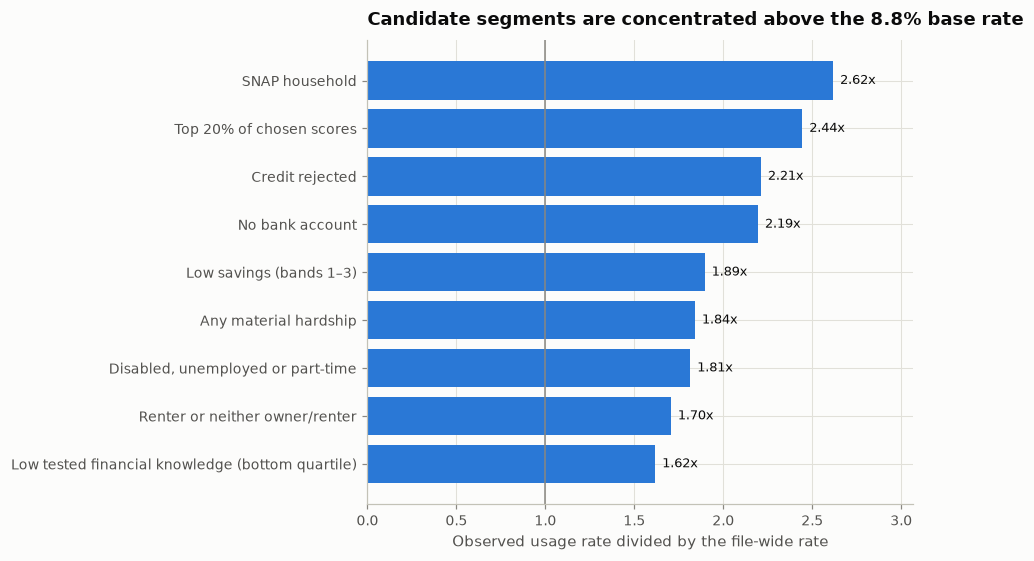

In [5]:
plot_segments = train_segments.sort_values("Lift vs file")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(plot_segments["Segment"], plot_segments["Lift vs file"], color=BLUE)
ax.axvline(1, color=MUTED, linewidth=1)
for i, v in enumerate(plot_segments["Lift vs file"]):
    ax.text(v + 0.04, i, f"{v:.2f}x", va="center", fontsize=8.5)
ax.set_xlabel("Observed usage rate divided by the file-wide rate")
ax.set_title("Candidate segments are concentrated above the 8.8% base rate")
ax.set_xlim(0, max(plot_segments["Lift vs file"]) + 0.45)
fig.tight_layout()
fig.savefig(FIG_DIR / "20_target_segments.png")
plt.show()

**Takeaways**

- The top 20% rule is the strongest single targeting segment: it has a 25.2% observed usage rate in the test set, about three times the overall usage rate, and catches about half of all users. Exact counts and rates are in the table above.
- No bank account, SNAP receipt, credit rejection, low savings, hardship, and lower knowledge each identify groups with above-average usage. Their overlap means they should be combined into a score or needs-based offer, not stacked as independent customer counts.
- Test-set rates broadly confirm the training OOF pattern, but subgroup rates vary because some groups are small. Use the model for ranking and validation, not as a guarantee for any individual.

# 4. Reachability: what can a card company observe?

The selected-feature table marks each predictor as observable by a card company (`Yes` or `Partly`) or survey-only. The observable model below uses the same logistic-regression approach and the same top-20% rule, but excludes all survey-only variables. It is evaluated with out-of-fold training scores and a separately fitted test score.

In [6]:
observable_features = features.index[features["available_to_card_company"] != "Survey only"].tolist()
survey_only_features = features.index[features["available_to_card_company"] == "Survey only"].tolist()
print(f"Observable or partly observable predictors: {len(observable_features)}")
print(", ".join(observable_features))
print(f"Excluded survey-only predictors: {len(survey_only_features)}")

scaled, binary, nominal = feature_lists()
def subset_preprocessor(columns):
    columns = list(columns)
    return ColumnTransformer([
        ("scaled", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), [c for c in scaled if c in columns]),
        ("binary", SimpleImputer(strategy="most_frequent"), [c for c in binary if c in columns]),
        ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), [c for c in nominal if c in columns]),
    ], remainder="drop", verbose_feature_names_out=False)

observable_model = Pipeline([
    ("prep", subset_preprocessor(observable_features)),
    ("model", LogisticRegression(C=10, class_weight="balanced", max_iter=5000, random_state=SEED)),
])
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
observable_oof = cross_val_predict(observable_model, X_train[observable_features], y_train, cv=folds, method="predict_proba")[:, 1]
observable_model.fit(X_train[observable_features], y_train)
observable_test = observable_model.predict_proba(X_test[observable_features])[:, 1]

full_train_flag = train_scores["score_chosen"].to_numpy() >= threshold
full_test_flag = test_scores["score_chosen"].to_numpy() >= threshold
observable_train_cutoff = float(np.quantile(observable_oof, 1 - TOP_SHARE))
observable_test_flag = observable_test >= observable_train_cutoff
observable_train_flag = observable_oof >= observable_train_cutoff

def targeting_metrics(y, flag, overall):
    y, flag = np.asarray(y), np.asarray(flag)
    hits = int((flag & (y == 1)).sum())
    return {"People flagged": int(flag.sum()), "Share flagged": flag.mean(), "Usage rate among flagged": y[flag].mean(),
            "Recall": hits / int((y == 1).sum()), "Lift": y[flag].mean() / overall}

reachability = pd.DataFrame([
    {"Model and file": "All 20 predictors — training OOF", **targeting_metrics(y_train, full_train_flag, base_rate)},
    {"Model and file": "Observable predictors — training OOF", **targeting_metrics(y_train, observable_train_flag, base_rate)},
    {"Model and file": "All 20 predictors — test", **targeting_metrics(y_test, full_test_flag, y_test.mean())},
    {"Model and file": "Observable predictors — test", **targeting_metrics(y_test, observable_test_flag, y_test.mean())},
])
display(fmt(reachability, {"Share flagged": "{:.1%}", "Usage rate among flagged": "{:.1%}", "Recall": "{:.1%}", "Lift": "{:.2f}x"}))
print(f"Observable-only training cutoff: {observable_train_cutoff:.3f}; it is fixed from training OOF scores before test confirmation.")

Observable or partly observable predictors: 12
PPINCIMP, agecat, PPEDUC, HOUSING, EMPLOY, PPMARIT, PRODHAVE_1, PRODHAVE_4, PRODHAVE_3, COLLECT, REJECTED_1, MANAGE1_1
Excluded survey-only predictors: 8


,Model and file,People flagged,Share flagged,Usage rate among flagged,Recall,Lift
0,All 20 predictors — training OOF,1019,20.0%,21.5%,48.9%,2.44x
1,Observable predictors — training OOF,1019,20.0%,21.0%,47.8%,2.39x
2,All 20 predictors — test,246,19.3%,25.2%,55.4%,2.87x
3,Observable predictors — test,258,20.3%,21.7%,50.0%,2.47x


Observable-only training cutoff: 0.604; it is fixed from training OOF scores before test confirmation.


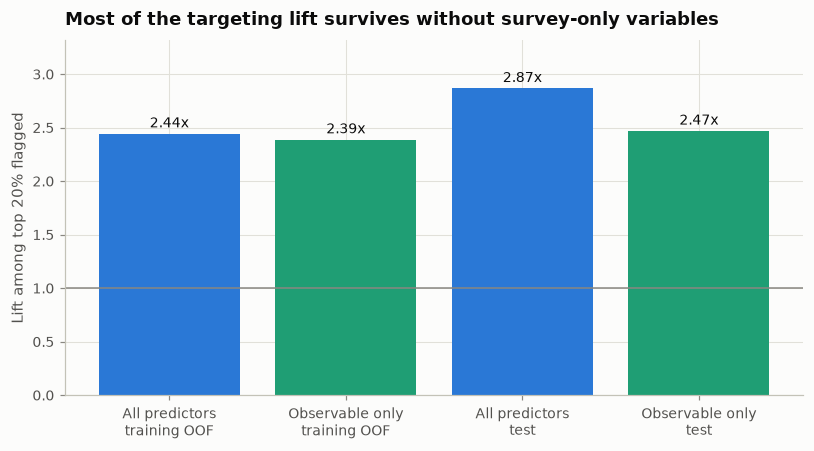

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
labels = ["All predictors\ntraining OOF", "Observable only\ntraining OOF", "All predictors\ntest", "Observable only\ntest"]
vals = reachability["Lift"].to_numpy()
colors = [BLUE, "#1f9e74", BLUE, "#1f9e74"]
bars = ax.bar(labels, vals, color=colors)
ax.axhline(1, color=MUTED, linewidth=1)
for bar, value in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.06, f"{value:.2f}x", ha="center", fontsize=9)
ax.set_ylabel("Lift among top 20% flagged")
ax.set_title("Most of the targeting lift survives without survey-only variables")
ax.set_ylim(0, max(vals) + 0.45)
fig.tight_layout()
fig.savefig(FIG_DIR / "21_reachability_lift.png")
plt.show()

**Takeaways**

- A company can build a useful first-pass campaign from bank-account and other product status, housing, income, age, education, employment, credit distress, and payment-history data. These are the 12 observable or partly observable predictors listed above.
- The observable-only model preserves nearly all of the full model’s top-20% lift and about half of users’ recall in both training OOF and test confirmation. Survey-only knowledge, savings, hardship, and shock measures improve context but are not required for initial reach.
- For a real campaign, use only data collected lawfully for the stated purpose, audit subgroup outcomes, and avoid using protected characteristics as targeting variables.

# 5. Recommended marketing and origination strategy

The model supports a **needs-aware, transparent acquisition strategy**, not automatic approval or a high-fee upsell. The score is a ranking signal for where to offer a clearly explained product and where to test a lower-cost alternative.

In [8]:
strategy = pd.DataFrame([
    ["Who to target", "Top 20% by chosen score; prioritize observable combinations of no bank account, credit distress, unstable access, and housing/income strain.", "The test top 20% usage rate and lift are shown above; the observable model is close behind."],
    ["Channels", "Employer/payroll, benefits and community partners, credit-repair or debt-support referrals, and digital acquisition using lawful first-party/application data.", "SNAP, credit distress, employment, and bank-account signals identify need; channel choice is a reasoned business proposal, not measured causality."],
    ["Message", "Lead with predictable access, transparent fees, direct deposit, budgeting controls, and a low-cost comparison—not urgency or scarcity.", "Higher scores overlap with liquidity and hardship signals; those prospects may be fee-sensitive."],
    ["Origination", "Use the score for outreach and product matching, not as a sole approval rule. Offer fee-free or low-fee paths, clear eligibility, and an alternative if a bank account is cheaper.", "The model ranks use likelihood only; it does not measure ability to pay fees, profitability, or suitability."],
    ["Measurement", "Track conversion, repeat use, complaints, fee incidence, overdraft/decline outcomes, and subgroup differences; compare offers with a controlled pilot.", "Test-set precision is moderate, so campaign learning is necessary and individual predictions are uncertain."],
], columns=["Decision", "Recommendation", "Evidence and boundary"])
display(strategy)

opportunity = pd.DataFrame({
    "Measure": ["Test respondents", "Test prepaid users", "Top-20% flagged", "Users in top-20%", "Usage rate among top-20%", "Lift vs test base rate"],
    "Value": [len(test_raw), int(y_test.sum()), int(full_test_flag.sum()), int(y_test[full_test_flag].sum()), y_test[full_test_flag].mean(), y_test[full_test_flag].mean() / y_test.mean()],
})
opportunity_display = opportunity.copy()
opportunity_display["Value"] = [
    f"{int(len(test_raw)):,}", f"{int(y_test.sum()):,}", f"{int(full_test_flag.sum()):,}",
    f"{int(y_test[full_test_flag].sum()):,}", f"{y_test[full_test_flag].mean():.1%}",
    f"{y_test[full_test_flag].mean() / y_test.mean():.2f}x",
]
display(opportunity_display)

,Decision,Recommendation,Evidence and boundary
0,Who to target,"Top 20% by chosen score; prioritize observable combinations of no bank account, credit distress, unstable ...",The test top 20% usage rate and lift are shown above; the observable model is close behind.
1,Channels,"Employer/payroll, benefits and community partners, credit-repair or debt-support referrals, and digital ac...","SNAP, credit distress, employment, and bank-account signals identify need; channel choice is a reasoned bu..."
2,Message,"Lead with predictable access, transparent fees, direct deposit, budgeting controls, and a low-cost compari...",Higher scores overlap with liquidity and hardship signals; those prospects may be fee-sensitive.
3,Origination,"Use the score for outreach and product matching, not as a sole approval rule. Offer fee-free or low-fee pa...","The model ranks use likelihood only; it does not measure ability to pay fees, profitability, or suitability."
4,Measurement,"Track conversion, repeat use, complaints, fee incidence, overdraft/decline outcomes, and subgroup differen...","Test-set precision is moderate, so campaign learning is necessary and individual predictions are uncertain."


,Measure,Value
0,Test respondents,"1,274"
1,Test prepaid users,112
2,Top-20% flagged,246
3,Users in top-20%,62
4,Usage rate among top-20%,25.2%
5,Lift vs test base rate,2.87x


### Responsible marketing

Race/ethnicity is not a predictor and must not be used as a targeting variable. Nevertheless, predictors such as income, housing, bank-account access, and credit distress can produce different reach rates across racial/ethnic groups because social and economic conditions are unevenly distributed. Therefore, a campaign should monitor approval, offer, fee, complaint, and retention outcomes by group, provide the same transparent terms, and investigate disparities rather than treat them as evidence of different intrinsic demand.

The same high-score groups are also the groups most likely to be financially fragile. That overlap is commercially relevant but ethically important: the people most likely to accept the product may also be least able to absorb fees. Product design, disclosures, and alternatives are part of the strategy—not post-sale afterthoughts.

# 6. Conclusions and limitations for the card company

**Conclusion.** The model supports a targeted marketing strategy, but only as a moderate ranking tool. Focus on the top fifth of scores, use observable financial-access and distress signals to reach prospects, and validate the strategy with transparent, low-cost offers. The strongest business insight is not “target the unbanked”: most users are banked, so the addressable market includes mainstream customers seeking liquidity, control, or an alternative transaction tool.

**Limitations.** The data are a 2016 self-reported survey; the outcome records whether a respondent used a reloadable prepaid card, not frequency, fees paid, profitability, or product suitability. Results ignore survey weights and are therefore not national population estimates. Associations do not establish causes. The model’s moderate performance means many people flagged will not be users and many users will be missed. The score should support outreach and learning, never automatic approval, pricing, or a claim that a person is financially unsophisticated.

### Task C hand-off

- `score_chosen` in `data/train_oof_scores.csv` is the leakage-safe training ranking for profiling; `data/test_scores.csv` is the final confirmation set.
- The chosen model is the class-weighted logistic regression with `C=10`; the top-20% cutoff is fixed from training scores and is about `0.600`.
- Figures saved by this notebook: `figures/19_score_associations.png`, `figures/20_target_segments.png`, and `figures/21_reachability_lift.png`.